In [4]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

CLASS_NAMES = ["T-shirt/top","Trouser","Pullover","Dress","Coat",
               "Sandal","Shirt","Sneaker","Bag","Ankle boot"]

(x_tr, y_tr), (x_te, y_te) = keras.datasets.fashion_mnist.load_data()
x_tr = (x_tr.astype("float32")/255.0)[..., None]
x_te = (x_te.astype("float32")/255.0)[..., None]
print(x_tr.shape, x_te.shape)

(60000, 28, 28, 1) (10000, 28, 28, 1)


In [5]:
dense = keras.Sequential([
    layers.Input(shape=(28,28,1)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
dense.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = dense.fit(x_tr, y_tr, epochs=10, batch_size=128, validation_split=0.1)
print("Dense test accuracy:", dense.evaluate(x_te, y_te, verbose=0)[1])

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7976 - loss: 0.5698 - val_accuracy: 0.8553 - val_loss: 0.3995
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8505 - loss: 0.4128 - val_accuracy: 0.8658 - val_loss: 0.3635
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8637 - loss: 0.3725 - val_accuracy: 0.8767 - val_loss: 0.3470
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8693 - loss: 0.3545 - val_accuracy: 0.8765 - val_loss: 0.3419
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8751 - loss: 0.3367 - val_accuracy: 0.8712 - val_loss: 0.3413
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8787 - loss: 0.3251 - val_accuracy: 0.8803 - val_loss: 0.3254
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8819 - loss: 0.3156 - val_accuracy: 0.8832 - val_loss: 0.3122
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8884 - loss: 0.3020 - val_accuracy: 0.

In [16]:
cnn = keras.Sequential([
    layers.Input(shape=(28,28,1)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.4),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
cnn.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])

early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                      restore_best_weights=True)
h2 = cnn.fit(x_tr, y_tr, epochs=20, batch_size=128,
             validation_split=0.1, callbacks=[early])
print("CNN test accuracy:", cnn.evaluate(x_te, y_te, verbose=0)[1])

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 31s 66ms/step - accuracy: 0.7856 - loss: 0.5915 - val_accuracy: 0.6108 - val_loss: 1.1525
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 28s 66ms/step - accuracy: 0.8630 - loss: 0.3727 - val_accuracy: 0.8938 - val_loss: 0.2753
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 26s 62ms/step - accuracy: 0.8815 - loss: 0.3217 - val_accuracy: 0.9050 - val_loss: 0.2668
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 26s 62ms/step - accuracy: 0.8927 - loss: 0.2945 - val_accuracy: 0.9085 - val_loss: 0.2472
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 26s 62ms/step - accuracy: 0.8981 - loss: 0.2741 - val_accuracy: 0.9095 - val_loss: 0.2439
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 27s 63ms/step - accuracy: 0.9038 - loss: 0.2595 - val_accuracy: 0.9115 - val_loss: 0.2377
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 27s 64ms/step - accuracy: 0.9084 - loss: 0.2469 - val_accuracy: 0.9192 - val_loss: 0.2227
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 27s 65ms/step - accuracy: 0.9123 - loss: 0.2389 - 

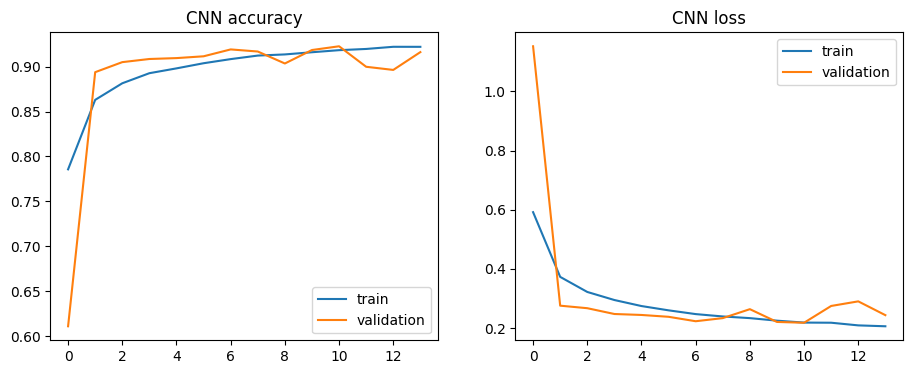

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(h2.history["accuracy"], label="train")
ax[0].plot(h2.history["val_accuracy"], label="validation")
ax[0].set_title("CNN accuracy"); ax[0].legend()
ax[1].plot(h2.history["loss"], label="train")
ax[1].plot(h2.history["val_loss"], label="validation")
ax[1].set_title("CNN loss"); ax[1].legend()
plt.show()

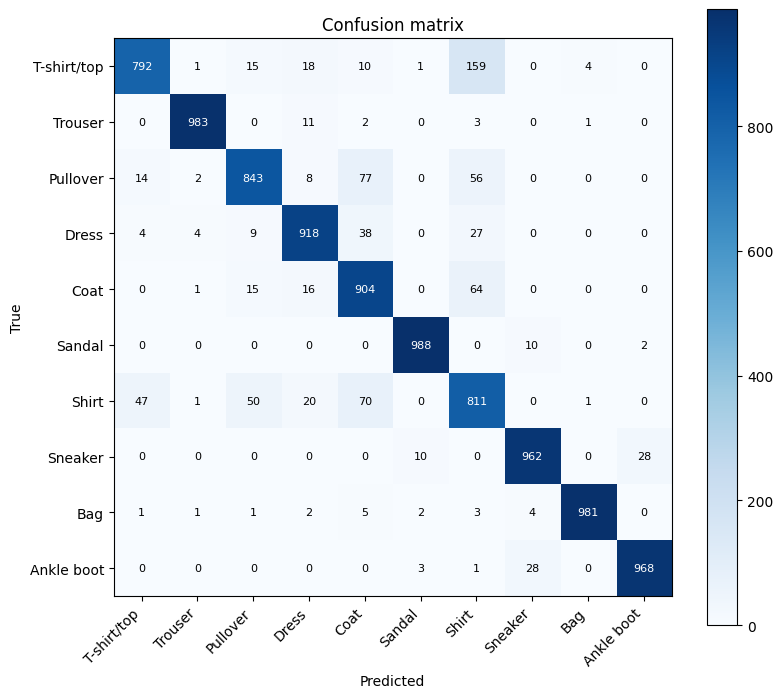

In [18]:
y_pred = np.argmax(cnn.predict(x_te, verbose=0), axis=1)
cm = np.zeros((10,10), dtype=int)
for t, p in zip(y_te, y_pred):
    cm[t, p] += 1

plt.figure(figsize=(9,8))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(10), CLASS_NAMES, rotation=45, ha="right")
plt.yticks(range(10), CLASS_NAMES)
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i,j], ha="center", va="center", fontsize=8,
                 color="white" if cm[i,j] > cm.max()/2 else "black")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix")
plt.show()

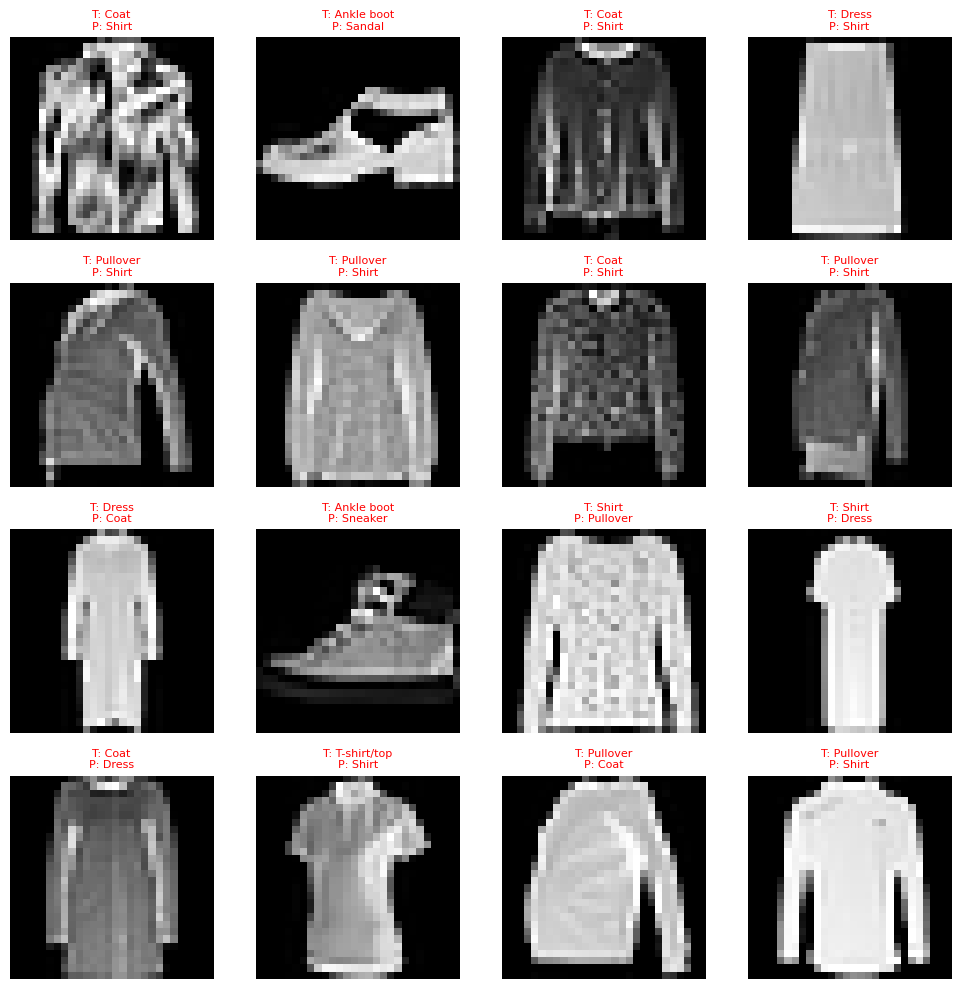

In [19]:
wrong = np.where(y_pred != y_te)[0][:16]
plt.figure(figsize=(10,10))
for k, idx in enumerate(wrong):
    plt.subplot(4,4,k+1)
    plt.imshow(x_te[idx].squeeze(), cmap="gray")
    plt.title(f"T: {CLASS_NAMES[y_te[idx]]}\nP: {CLASS_NAMES[y_pred[idx]]}",
              fontsize=8, color="red")
    plt.axis("off")
plt.tight_layout(); plt.show()

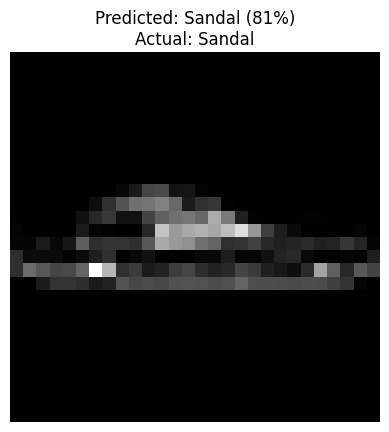

In [20]:
i = np.random.randint(len(x_te))
probs = cnn.predict(x_te[i:i+1], verbose=0)[0]
plt.imshow(x_te[i].squeeze(), cmap="gray")
plt.title(f"Predicted: {CLASS_NAMES[np.argmax(probs)]} ({probs.max():.0%})\n"
          f"Actual: {CLASS_NAMES[y_te[i]]}")
plt.axis("off"); plt.show()

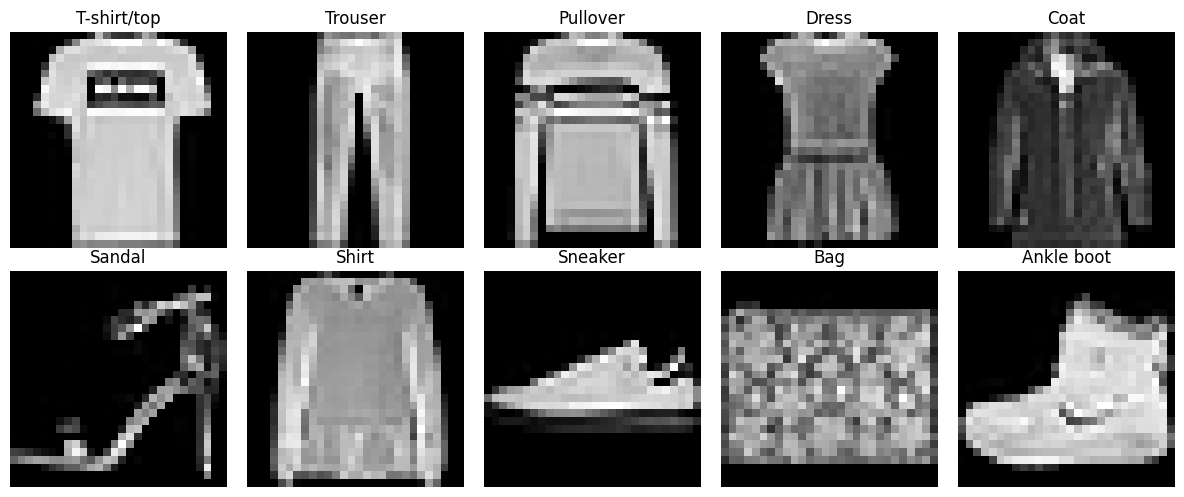

In [21]:
plt.figure(figsize=(12,5))
for c in range(10):
    idx = np.where(y_tr == c)[0][0]
    plt.subplot(2,5,c+1)
    plt.imshow(x_tr[idx].squeeze(), cmap="gray")
    plt.title(CLASS_NAMES[c])
    plt.axis("off")
plt.tight_layout(); plt.show()

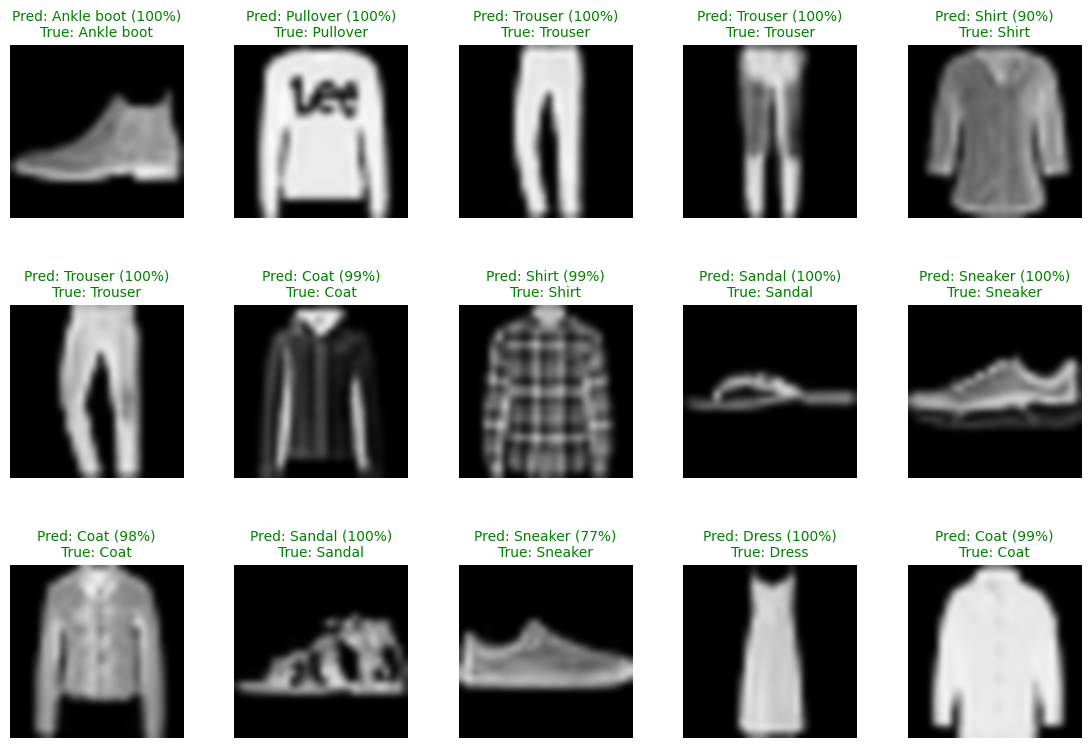

In [22]:
plt.figure(figsize=(14,9))
for k in range(15):
    probs = cnn.predict(x_te[k:k+1], verbose=0)[0]
    pred = np.argmax(probs)
    plt.subplot(3,5,k+1)
    plt.imshow(x_te[k].squeeze(), cmap="gray", interpolation="bicubic")
    plt.title(f"Pred: {CLASS_NAMES[pred]} ({probs[pred]:.0%})\nTrue: {CLASS_NAMES[y_te[k]]}",
              color="green" if pred == y_te[k] else "red", fontsize=10)
    plt.axis("off")
plt.subplots_adjust(hspace=0.5, wspace=0.2)
plt.show()

In [23]:
cnn.save("fashion_cnn.keras")

In [24]:
print("Dense test accuracy:", dense.evaluate(x_te, y_te, verbose=0)[1])
print("CNN test accuracy:  ", cnn.evaluate(x_te, y_te, verbose=0)[1])

Dense test accuracy: 0.8744999766349792
CNN test accuracy:   0.9150000214576721
